# Walkthrough: five formula pairs through every stage

This notebook follows five pairs from the ATIC manual review through the whole checker, showing every
intermediate product:

| stage | what you see |
|---|---|
| **1 Parse** | tokens and the syntax tree (AST) of gold and prediction |
| **2 Normalise** | signal types, `b = 1 → b`, time scaling, the normalised AST |
| **3 Syntactic** | canonical forms and whether they coincide |
| **4 SPOT** | past elimination, predicate abstraction and axioms, the LTL actually sent to SPOT, automaton sizes, the two containment checks, a counterexample trace |
| **5 STLSat** | horizon capping, past elimination, until rewrite, the two SAT queries, raw solver output, a counterexample trace |
| **6 Verdict** | the result of the real pipeline (`Checker`) for comparison |

The five pairs are chosen to exercise different parts of the machinery:

| # | pair | what it exercises | verdict |
|---|---|---|---|
| A | MR-001 | Boolean shorthand `p = 1` vs `p` → solved by the syntactic stage | EQUIVALENT |
| B | MR-020 | numeric predicates, negation of an interval → predicate abstraction + ordering axioms | EQUIVALENT |
| C | MR-065 | `rise()` on both sides → auxiliary "yesterday" signals | PRED_STRONGER |
| D | MR-019 | bounded until with an arithmetic term `x1 + x2` → X-chains in SPOT, until rewrite for STLSat | PRED_WEAKER |
| E | MR-015 | unbounded `F` → exact in SPOT, horizon-capped in STLSat | PRED_WEAKER |

The mathematics behind each step is explained on the explainer page and in the module docstrings.

## Setup and helpers
The helpers only *display* what the package computes; all transformations are the package's own functions.

In [1]:
import re, subprocess, tempfile, html
from pathlib import Path
import pandas as pd
import spot, buddy
from IPython.display import display, Markdown, SVG, HTML

from equivalence.parser import parse, preprocess, tokenize
from equivalence.ast import (to_str, term_str, Prop, PredApp, Cmp, Not, And, Or, Implies, Iff,
                             Unary, Binary, Edge, Indexed, BoolConst, future_horizon)
from equivalence.normalize import normalise_pair, canonical, infer_types, booleanize
from equivalence.past import PastEliminator, Definition
from equivalence.atoms import PredicateAbstraction
from equivalence import spot_backend, stlsat_backend, semantics
from equivalence.datasets import load_manual_review
from equivalence.pipeline import Checker, Config

pd.set_option('display.max_colwidth', 140)
MR = load_manual_review().set_index('pair_id')
SYM = {'distance'}

# ---------- AST drawing (graphviz `dot`) ----------
COL = {'temporal': '#2a78d6', 'past': '#1baf7a', 'bool': '#6b7080', 'atom': '#eb6834'}
def _ast_dot(f, title):
    lines, n = [f'digraph G {{ labelloc="t"; label="{title}"; fontname="Helvetica"; node [fontname="Helvetica", fontsize=11]; edge [arrowsize=0.6];'], [0]
    def node(label, kind, shape='box'):
        i = n[0]; n[0] += 1
        c = COL[kind]
        lines.append(f'n{i} [label="{html.escape(label)}", shape={shape}, style="rounded,filled", fillcolor="{c}22", color="{c}"];')
        return i
    def rec(g):
        if isinstance(g, (Prop, PredApp, Cmp, BoolConst)):
            return node(to_str(g).strip('()'), 'atom', 'box')
        if isinstance(g, Unary):
            i = node(f'{g.op}{g.interval}', 'past' if g.op in 'HOY' else 'temporal', 'ellipse')
        elif isinstance(g, Binary):
            i = node(f'{g.op}{g.interval}', 'past' if g.op == 'S' else 'temporal', 'ellipse')
        elif isinstance(g, Edge):
            i = node(g.kind, 'past', 'ellipse')
        elif isinstance(g, Indexed):
            i = node(f'{g.kind}_{g.index}', 'bool', 'ellipse')
        else:
            i = node({Not: '¬', And: '∧', Or: '∨', Implies: '→', Iff: '↔'}[type(g)], 'bool', 'circle')
        kids = (g.arg,) if hasattr(g, 'arg') else g.args if hasattr(g, 'args') else (g.left, g.right)
        for k in kids:
            lines.append(f'n{i} -> n{rec(k)};')
        return i
    rec(f); lines.append('}')
    return '\n'.join(lines)

def show_ast(f, title):
    svg = subprocess.run(['dot', '-Tsvg'], input=_ast_dot(f, title), capture_output=True, text=True).stdout
    display(SVG(svg))

def show_tokens(s, label):
    toks = [t for t in tokenize(preprocess(s)) if t.kind != 'eof']
    display(Markdown(f'**{label}** — {len(toks)} tokens: ' + ' '.join(f'`{t.val}`' for t in toks)))

def split_conj(q):
    # split a query at top-level '&&' for readability
    out, depth, cur, i = [], 0, '', 0
    while i < len(q):
        ch = q[i]
        depth += ch == '('; depth -= ch == ')'
        if depth == 0 and q.startswith(' && ', i):
            out.append(cur); cur = ''; i += 4; continue
        cur += ch; i += 1
    return out + [cur]

# ---------- SPOT counterexample decoding ----------
def spot_word_table(aut, steps=None):
    w = aut.accepting_word()
    if w is None:
        return None
    w.simplify()
    letters = [spot.bdd_format_formula(aut.get_dict(), buddy.bdd_satone(l)) for l in w.prefix]
    cyc = [spot.bdd_format_formula(aut.get_dict(), buddy.bdd_satone(l)) for l in w.cycle]
    steps = steps or min(len(letters) + len(cyc) + 1, 60)
    seq = letters + [cyc[i % len(cyc)] for i in range(max(0, steps - len(letters)))]
    rows = {}
    for t, lit in enumerate(seq[:steps]):
        for part in lit.split(' & '):
            part = part.strip()
            if part in ('1', '0', ''):
                continue
            neg = part.startswith('!')
            name = part.lstrip('!').strip('"')
            rows.setdefault(name, {})[t] = '0' if neg else '1'
    T = min(steps, len(seq))
    names = sorted(rows, key=lambda n: (n.startswith('aux__'), n))          # original signals first, aux last
    df = pd.DataFrame([[rows[n].get(t, '·') for t in range(T)] for n in names],
                      index=names, columns=[f't={t}' for t in range(T)])
    return df, len(letters), len(cyc)

def style_trace(df):
    return df.style.map(lambda v: 'background-color:#2a78d633' if v == '1' else ('color:#999' if v == '·' else ''))

# ---------- STLSat ----------
def stlsat_raw(query, engine='smt', extra=()):
    with tempfile.NamedTemporaryFile('w', suffix='.stl', delete=False) as f:
        f.write(query + '\n'); p = f.name
    out = subprocess.run(['stlsat', '--engine', engine, *extra, p], capture_output=True, text=True, timeout=120)
    Path(p).unlink()
    return (out.stdout + out.stderr).strip()

def stlsat_trace(query):
    # Counterexample from STLSat's --trace-extraction (tableau engine only; smt prints no model).
    # Boolean literals go into a signal x time grid; anything else (comparisons) is listed separately.
    raw = stlsat_raw(query, 'tableau', ['--trace-extraction'])
    steps = re.findall(r'^\s*\[(.*)\],?\s*$', raw, re.M)
    if not steps:
        return None, None
    grid, other = {}, {}
    for t, s_ in enumerate(steps):
        for lit in filter(None, (x.strip() for x in s_.split(', '))):
            m = re.fullmatch(r'\(!([A-Za-z_]\w*)\)|([A-Za-z_]\w*)', lit)
            if m:
                grid.setdefault(m.group(1) or m.group(2), {})[t] = '0' if m.group(1) else '1'
            else:
                other.setdefault(t, set()).add(lit)
    T = len(steps)
    names = sorted(grid, key=lambda n: (n.startswith('aux__'), n))
    df = pd.DataFrame([[grid[n].get(t, '·') for t in range(T)] for n in names], index=names, columns=[f't={t}' for t in range(T)])
    oth = pd.DataFrame([{'t': t, 'other literals': ', '.join(sorted(v))} for t, v in sorted(other.items())])
    return df, oth


class Walkthrough:
    def __init__(self, pair_id):
        r = MR.loc[pair_id]
        self.id, self.gold_s, self.pred_s, self.ctx = pair_id, r.gold, r.pred, r.context
        display(Markdown(f"**{pair_id}** · human decision: `{r.final_decision}`\n\n"
                         f"- gold: `{self.gold_s}`\n- pred: `{self.pred_s}`\n- signal context: _{self.ctx}_"))

    # 1 ------------------------------------------------------------------
    def parse(self):
        show_tokens(self.gold_s, 'gold'); show_tokens(self.pred_s, 'pred')
        self.g0, self.p0 = parse(self.gold_s), parse(self.pred_s)
        show_ast(self.g0, 'gold (parsed)'); show_ast(self.p0, 'pred (parsed)')

    # 2 ------------------------------------------------------------------
    def normalise(self):
        n = normalise_pair(self.g0, self.p0, self.ctx)
        self.g, self.p = n.gold, n.pred
        display(Markdown(
            f"- type source: **{n.env.source}**\n- Boolean signals: `{sorted(n.env.boolean)}`\n"
            f"- numeric signals: `{sorted(n.env.numeric)}`\n- time scale factor: **{n.time_scale}**"
            + (f" ({'; '.join(n.notes)})" if n.notes else " (all bounds already integers)")))
        display(pd.DataFrame({'before': [to_str(self.g0), to_str(self.p0)], 'after normalisation': [to_str(self.g), to_str(self.p)]},
                             index=['gold', 'pred']))
        if to_str(self.g0) != to_str(self.g) or to_str(self.p0) != to_str(self.p):
            show_ast(self.g, 'gold (normalised)'); show_ast(self.p, 'pred (normalised)')
        else:
            display(Markdown('_Normalisation changed nothing for this pair._'))

    # 3 ------------------------------------------------------------------
    def syntactic(self):
        cg, cp = to_str(canonical(self.g, SYM)), to_str(canonical(self.p, SYM))
        display(pd.DataFrame({'canonical form': [cg, cp]}, index=['gold', 'pred']))
        display(Markdown(f"Canonical forms {'**identical → EQUIVALENT proven, no solver needed**' if cg == cp else '**differ** → this proves nothing; go to the solvers'}."))

    # 4 ------------------------------------------------------------------
    def spot(self, draw_limit=14):
        display(Markdown('#### 4a  Past elimination'))
        pe = PastEliminator()
        ge, pe_ = pe.eliminate(self.g), pe.eliminate(self.p)
        if pe.defs:
            display(pd.DataFrame([{'aux signal': d.aux, 'definition': f'{d.aux} ≡ Y({to_str(d.expr)})' if d.kind == 'Y' else f'{d.aux} ≡ {to_str(d.expr)}',
                                   'SPOT constraint': spot_backend.emit_definitions([d])[0]} for d in pe.defs]).set_index('aux signal'))
            display(pd.DataFrame({'past-free formula': [to_str(ge), to_str(pe_)]}, index=['gold', 'pred']))
        else:
            display(Markdown('_No past operators or edges: nothing to eliminate._'))

        display(Markdown('#### 4b  Predicate abstraction'))
        pa = PredicateAbstraction(SYM)
        ga, pa_ = pa.abstract(ge), pa.abstract(pe_)
        defs = [Definition(d.aux, d.kind, pa.abstract(d.expr)) for d in pe.defs]
        axioms = pa.axioms()
        exact, why = pa.exactness()
        if pa.atoms:
            display(pd.DataFrame([{'SPOT atom': f'"{name}"', 'stands for': f'{t} {op} {r}'} for (t, op, r), name in pa.atoms.items()]).set_index('SPOT atom'))
            display(Markdown('Ordering axioms: ' + (', '.join(f'`{to_str(a)}`' for a in axioms) if axioms else '_none needed (no two atoms over the same term)_')
                             + f'\n\nAbstraction exact: **{exact}** {why}'))
        else:
            display(Markdown('_Only Boolean signals: every atom is already a proposition._'))
        display(pd.DataFrame({'propositional formula': [to_str(ga), to_str(pa_)]}, index=['gold', 'pred']))

        display(Markdown('#### 4c  What SPOT receives'))
        q = spot_backend.build_query(ga, pa_, defs, axioms)
        display(Markdown(f"gold:\n```\n{q.gold}\n```\npred:\n```\n{q.pred}\n```"))

        display(Markdown('#### 4d  Automata and containment'))
        G, P = spot.formula(q.gold), spot.formula(q.pred)
        rows, self._spot_auts = [], {}
        for name, f in [('A ∧ gold', G), ('A ∧ pred', P), ('A ∧ gold ∧ ¬pred', spot.formula_And([G, spot.formula_Not(P)])),
                        ('A ∧ pred ∧ ¬gold', spot.formula_And([P, spot.formula_Not(G)]))]:
            aut = spot.translate(f)
            self._spot_auts[name] = aut
            rows.append({'automaton for': name, 'states': aut.num_states(), 'edges': aut.num_edges(),
                         'language empty?': aut.is_empty()})
        df = pd.DataFrame(rows).set_index('automaton for'); display(df)
        g_in_p, p_in_g = df.loc['A ∧ gold ∧ ¬pred', 'language empty?'], df.loc['A ∧ pred ∧ ¬gold', 'language empty?']
        display(Markdown(f"gold ⊆ pred: **{g_in_p}** &nbsp;&nbsp; pred ⊆ gold: **{p_in_g}**"))
        small = self._spot_auts['A ∧ gold']
        if small.num_states() <= draw_limit:
            display(Markdown('Büchi automaton for **A ∧ gold** (accepting edges marked; `!` = negation):'))
            display(small)
        for name in ('A ∧ gold ∧ ¬pred', 'A ∧ pred ∧ ¬gold'):
            res = spot_word_table(self._spot_auts[name])
            if res:
                tab, np_, nc = res
                shape = (f'steps 0–{np_ - 1}, then' if np_ else 'no prefix;') + f' a cycle of length {nc} repeated forever'
                display(Markdown(f"**Counterexample from `{name}`** — an infinite trace in lasso form ({shape}); `·` = don't care:"))
                display(style_trace(tab))

    # 5 ------------------------------------------------------------------
    def stlsat(self):
        display(Markdown('#### 5a  Unbounded operators → horizon'))
        g, p = self.g, self.p
        if stlsat_backend.has_unbounded(g) or stlsat_backend.has_unbounded(p):
            B = max(int(future_horizon(f, unbounded_as=0)) for f in (g, p))
            H = stlsat_backend.pair_horizon([g, p], 2, 10)
            g, p = stlsat_backend.cap_unbounded(g, H), stlsat_backend.cap_unbounded(p, H)
            display(Markdown(f'B = largest finite horizon = **{B}**, so H = 2·{B} + 10 = **{H}**. Verdict will be flagged `bounded_approx`.'))
            display(pd.DataFrame({'capped': [to_str(g), to_str(p)]}, index=['gold', 'pred']))
        else:
            display(Markdown('_All operators bounded: exact, no capping._'))
        display(Markdown('#### 5b  Past elimination + until rewrite (standard → STLSat-native inclusive)'))
        pe = PastEliminator()
        ge, pe_ = pe.eliminate(g), pe.eliminate(p)
        gi, pi = semantics.standard_to_inclusive(ge), semantics.standard_to_inclusive(pe_)
        defs = [Definition(d.aux, d.kind, semantics.standard_to_inclusive(d.expr)) for d in pe.defs]
        display(pd.DataFrame({'past-free': [to_str(ge), to_str(pe_)], 'after until rewrite': [to_str(gi), to_str(pi)]}, index=['gold', 'pred']))
        q1, q2, T = stlsat_backend.build_queries(gi, pi, defs)
        if defs:
            R = max(int(future_horizon(c)) for c in (gi, pi))
            display(Markdown(f'Definition window: formulas read up to R = **{R}**; T = R + Σ h(defs) + 1 = **{T}** → constraints on `G[0,{T - 1}]`.'))
        display(Markdown('#### 5c  The two queries (top-level conjuncts, one per line)'))
        for name, q in [('Q1 = A ∧ gold ∧ ¬pred', q1), ('Q2 = A ∧ pred ∧ ¬gold', q2)]:
            display(Markdown(f'**{name}**\n```\n' + '\n&& '.join(split_conj(q)) + '\n```'))
        display(Markdown('#### 5d  Solver output (engine smt)'))
        res = {}
        for name, q in [('Q1', q1), ('Q2', q2)]:
            raw = stlsat_raw(q)
            sat = 'Some(true)' in raw
            res[name] = sat
            display(Markdown(f"`{name}` → `{raw.splitlines()[0]}` ({raw.splitlines()[-1]}) ⇒ **{'SAT' if sat else 'UNSAT'}**"))
        display(Markdown(f"gold ⊆ pred: **{not res['Q1']}** &nbsp;&nbsp; pred ⊆ gold: **{not res['Q2']}**"))
        for name, q in [('Q1', q1), ('Q2', q2)]:
            if res[name]:
                grid, oth = stlsat_trace(q)
                if grid is None:
                    continue
                display(Markdown(f'**Counterexample for {name}** (from `--trace-extraction`, which only the tableau engine offers; a finite trace up to the horizon; `·` = not fixed by the solver):'))
                if len(grid):
                    display(style_trace(grid))
                if len(oth):
                    display(oth.set_index('t'))
                if not len(grid) and not len(oth):
                    display(Markdown('_The tableau trace fixes no literal at any step: for numeric constraints STLSat does not report concrete values, so it carries no information here._'))

    # 6 ------------------------------------------------------------------
    def verdict(self):
        with Checker() as c:
            r = c.check(self.gold_s, self.pred_s, self.ctx)
        keys = ['syntactic_equal', 'spot_status', 'spot_verdict', 'spot_ms', 'spot_exact',
                'stlsat_status', 'stlsat_verdict', 'stlsat_ms', 'stlsat_bounded_approx', 'stlsat_horizon']
        display(pd.Series({k: r.get(k) for k in keys}, name=self.id).to_frame())
        self.result = r
        return r

    def run_all(self):
        for title, fn in [('1 Parse', self.parse), ('2 Normalise', self.normalise), ('3 Syntactic stage', self.syntactic),
                          ('4 SPOT', self.spot), ('5 STLSat', self.stlsat), ('6 Pipeline verdict', self.verdict)]:
            display(Markdown(f'### {title}')); fn()

---
## A · MR-001 — Boolean shorthand

Gold writes every pump as `pump = 1`, the prediction writes the bare signal. The signal context declares all three Boolean, so normalisation rewrites `pump = 1 → pump`, and the canonical forms coincide. **No solver is needed.** The solver stages still run here to show they agree. The SPOT automaton is small enough to draw.

In [2]:
wA = Walkthrough('MR-001')

**MR-001** · human decision: `pass_equivalent`

- gold: `G((pump_primary = 1) | (pump_secondary = 1) | (pump_emergency = 1))`
- pred: `G(pump_primary | pump_secondary | pump_emergency)`
- signal context: _Boolean (1=true, 0=false): `pump_primary`, `pump_secondary`, `pump_emergency`. Time: seconds. Use these exact identifiers; do not create aliases._

### A.1 Parse

**gold** — 20 tokens: `G` `(` `(` `pump_primary` `=` `1` `)` `|` `(` `pump_secondary` `=` `1` `)` `|` `(` `pump_emergency` `=` `1` `)` `)`

**pred** — 8 tokens: `G` `(` `pump_primary` `|` `pump_secondary` `|` `pump_emergency` `)`

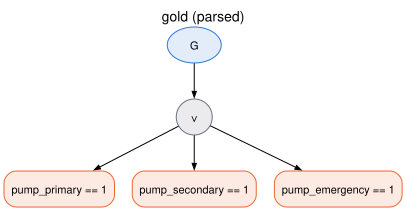

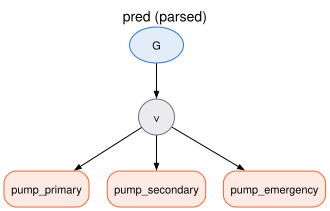

In [3]:
wA.parse()

### A.2 Normalise

- type source: **context**
- Boolean signals: `['pump_emergency', 'pump_primary', 'pump_secondary']`
- numeric signals: `[]`
- time scale factor: **1** (all bounds already integers)

,before,after normalisation
gold,G(((pump_primary == 1) | (pump_secondary == 1) | (pump_emergency == 1))),G((pump_primary | pump_secondary | pump_emergency))
pred,G((pump_primary | pump_secondary | pump_emergency)),G((pump_primary | pump_secondary | pump_emergency))


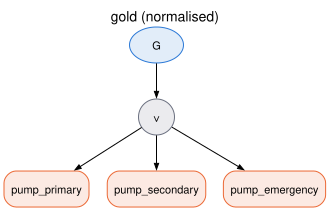

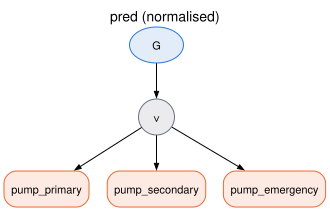

In [4]:
wA.normalise()

### A.3 Syntactic stage

In [5]:
wA.syntactic()

,canonical form
gold,G((pump_emergency | pump_primary | pump_secondary))
pred,G((pump_emergency | pump_primary | pump_secondary))


Canonical forms **identical → EQUIVALENT proven, no solver needed**.

### A.4 SPOT

#### 4a  Past elimination

_No past operators or edges: nothing to eliminate._

#### 4b  Predicate abstraction

_Only Boolean signals: every atom is already a proposition._

,propositional formula
gold,G((pump_primary | pump_secondary | pump_emergency))
pred,G((pump_primary | pump_secondary | pump_emergency))


#### 4c  What SPOT receives

gold:
```
G((("pump_primary") | ("pump_secondary") | ("pump_emergency")))
```
pred:
```
G((("pump_primary") | ("pump_secondary") | ("pump_emergency")))
```

#### 4d  Automata and containment

,states,edges,language empty?
automaton for,,,
A ∧ gold,1,1,False
A ∧ pred,1,1,False
A ∧ gold ∧ ¬pred,1,0,True
A ∧ pred ∧ ¬gold,1,0,True


gold ⊆ pred: **True** &nbsp;&nbsp; pred ⊆ gold: **True**

Büchi automaton for **A ∧ gold** (accepting edges marked; `!` = negation):

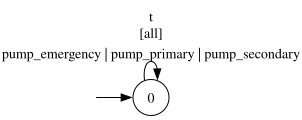

In [6]:
wA.spot()

### A.5 STLSat

In [7]:
wA.stlsat()

#### 5a  Unbounded operators → horizon

B = largest finite horizon = **0**, so H = 2·0 + 10 = **10**. Verdict will be flagged `bounded_approx`.

,capped
gold,"G[0,10]((pump_primary | pump_secondary | pump_emergency))"
pred,"G[0,10]((pump_primary | pump_secondary | pump_emergency))"


#### 5b  Past elimination + until rewrite (standard → STLSat-native inclusive)

,past-free,after until rewrite
gold,"G[0,10]((pump_primary | pump_secondary | pump_emergency))","G[0,10]((pump_primary | pump_secondary | pump_emergency))"
pred,"G[0,10]((pump_primary | pump_secondary | pump_emergency))","G[0,10]((pump_primary | pump_secondary | pump_emergency))"


#### 5c  The two queries (top-level conjuncts, one per line)

... (2 outputs left out)

#### 5d  Solver output (engine smt)

`Q1` → `SMT result: Some(false)` (DURATION_SEC: 0.038788) ⇒ **UNSAT**

`Q2` → `SMT result: Some(false)` (DURATION_SEC: 0.007978) ⇒ **UNSAT**

gold ⊆ pred: **True** &nbsp;&nbsp; pred ⊆ gold: **True**

### A.6 Pipeline verdict

In [8]:
wA.verdict();

,MR-001
syntactic_equal,True
spot_status,OK
spot_verdict,EQUIVALENT
spot_ms,0.135083
spot_exact,True
stlsat_status,OK
stlsat_verdict,EQUIVALENT
stlsat_ms,16.731
stlsat_bounded_approx,True
stlsat_horizon,10


---
## B · MR-020 — Numeric predicates and predicate abstraction

`!((t >= 20) & (t <= 30))` vs `t < 20 | t > 30`. Syntactically different, semantically identical over the reals. Watch stage 4b: the four comparisons collapse to two atoms, `t>=20` and `t>30`, plus the axiom `G(t>30 -> t>=20)`. That is enough for SPOT to prove equivalence. STLSat reasons about the real numbers directly. This is also the pair where STLSat's tableau engine gives a wrong answer, which is why the pipeline uses smt.

In [9]:
wB = Walkthrough('MR-020')

**MR-020** · human decision: `pass_equivalent`

- gold: `G((!((temperature >= 20) & (temperature <= 30))) -> F[0,6](G[0,4]((temperature >= 20) & (temperature <= 30))))`
- pred: `G((temperature < 20 | temperature > 30) -> F[0,6](G[0,4](temperature >= 20 & temperature <= 30)))`
- signal context: _Numeric: `temperature`. Time: seconds. Use these exact identifiers; do not create aliases._

### B.1 Parse

**gold** — 47 tokens: `G` `(` `(` `!` `(` `(` `temperature` `>=` `20` `)` `&` `(` `temperature` `<=` `30` `)` `)` `)` `->` `F` `[` `0` `,` `6` `]` `(` `G` `[` `0` `,` `4` `]` `(` `(` `temperature` `>=` `20` `)` `&` `(` `temperature` `<=` `30` `)` `)` `)` `)`

**pred** — 36 tokens: `G` `(` `(` `temperature` `<` `20` `|` `temperature` `>` `30` `)` `->` `F` `[` `0` `,` `6` `]` `(` `G` `[` `0` `,` `4` `]` `(` `temperature` `>=` `20` `&` `temperature` `<=` `30` `)` `)` `)`

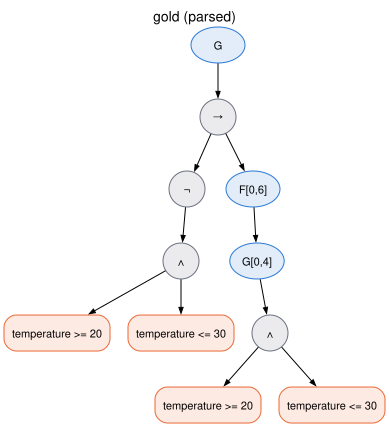

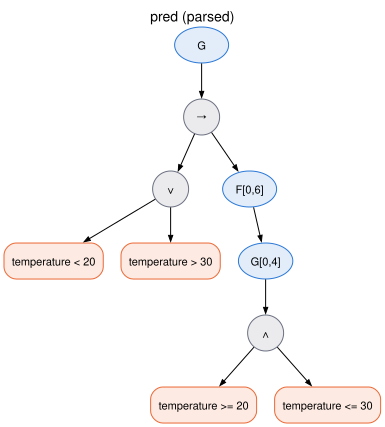

In [10]:
wB.parse()

### B.2 Normalise

In [11]:
wB.normalise()

- type source: **context**
- Boolean signals: `[]`
- numeric signals: `['temperature']`
- time scale factor: **1** (all bounds already integers)

,before,after normalisation
gold,"G((!((temperature >= 20) & (temperature <= 30)) -> F[0,6](G[0,4](((temperature >= 20) & (temperature <= 30))))))","G((!((temperature >= 20) & (temperature <= 30)) -> F[0,6](G[0,4](((temperature >= 20) & (temperature <= 30))))))"
pred,"G((((temperature < 20) | (temperature > 30)) -> F[0,6](G[0,4](((temperature >= 20) & (temperature <= 30))))))","G((((temperature < 20) | (temperature > 30)) -> F[0,6](G[0,4](((temperature >= 20) & (temperature <= 30))))))"


_Normalisation changed nothing for this pair._

### B.3 Syntactic stage

In [12]:
wB.syntactic()

,canonical form
gold,"G((!((temperature <= 30) & (temperature >= 20)) -> F[0,6](G[0,4](((temperature <= 30) & (temperature >= 20))))))"
pred,"G((((temperature < 20) | (temperature > 30)) -> F[0,6](G[0,4](((temperature <= 30) & (temperature >= 20))))))"


Canonical forms **differ** → this proves nothing; go to the solvers.

### B.4 SPOT

#### 4a  Past elimination

_No past operators or edges: nothing to eliminate._

#### 4b  Predicate abstraction

,stands for
SPOT atom,
"""temperature>=20""",temperature >= 20
"""temperature>30""",temperature > 30


Ordering axioms: `G((temperature>30 -> temperature>=20))`

Abstraction exact: **True** 

,propositional formula
gold,"G((!(temperature>=20 & !temperature>30) -> F[0,6](G[0,4]((temperature>=20 & !temperature>30)))))"
pred,"G(((!temperature>=20 | temperature>30) -> F[0,6](G[0,4]((temperature>=20 & !temperature>30)))))"


... (2 outputs left out)

#### 4d  Automata and containment

,states,edges,language empty?
automaton for,,,
A ∧ gold,11,17,False
A ∧ pred,11,17,False
A ∧ gold ∧ ¬pred,1,0,True
A ∧ pred ∧ ¬gold,1,0,True


gold ⊆ pred: **True** &nbsp;&nbsp; pred ⊆ gold: **True**

Büchi automaton for **A ∧ gold** (accepting edges marked; `!` = negation):

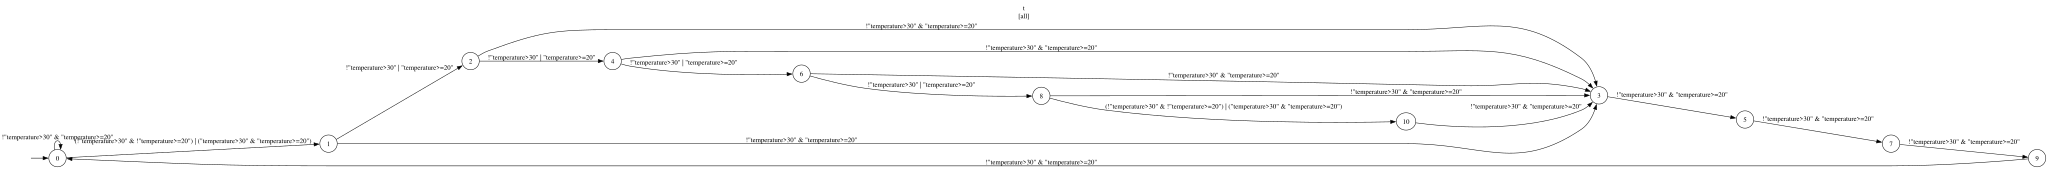

In [13]:
wB.spot()

### B.5 STLSat

In [14]:
wB.stlsat()

#### 5a  Unbounded operators → horizon

B = largest finite horizon = **10**, so H = 2·10 + 10 = **30**. Verdict will be flagged `bounded_approx`.

,capped
gold,"G[0,30]((!((temperature >= 20) & (temperature <= 30)) -> F[0,6](G[0,4](((temperature >= 20) & (temperature <= 30))))))"
pred,"G[0,30]((((temperature < 20) | (temperature > 30)) -> F[0,6](G[0,4](((temperature >= 20) & (temperature <= 30))))))"


#### 5b  Past elimination + until rewrite (standard → STLSat-native inclusive)

,past-free,after until rewrite
gold,"G[0,30]((!((temperature >= 20) & (temperature <= 30)) -> F[0,6](G[0,4](((temperature >= 20) & (temperature <= 30))))))","G[0,30]((!((temperature >= 20) & (temperature <= 30)) -> F[0,6](G[0,4](((temperature >= 20) & (temperature <= 30))))))"
pred,"G[0,30]((((temperature < 20) | (temperature > 30)) -> F[0,6](G[0,4](((temperature >= 20) & (temperature <= 30))))))","G[0,30]((((temperature < 20) | (temperature > 30)) -> F[0,6](G[0,4](((temperature >= 20) & (temperature <= 30))))))"


#### 5c  The two queries (top-level conjuncts, one per line)

... (2 outputs left out)

#### 5d  Solver output (engine smt)

`Q1` → `SMT result: Some(false)` (DURATION_SEC: 0.033005) ⇒ **UNSAT**

`Q2` → `SMT result: Some(false)` (DURATION_SEC: 0.014608) ⇒ **UNSAT**

gold ⊆ pred: **True** &nbsp;&nbsp; pred ⊆ gold: **True**

### B.6 Pipeline verdict

In [15]:
wB.verdict();

,MR-020
syntactic_equal,False
spot_status,OK
spot_verdict,EQUIVALENT
spot_ms,4.193917
spot_exact,True
stlsat_status,OK
stlsat_verdict,EQUIVALENT
stlsat_ms,37.569
stlsat_bounded_approx,True
stlsat_horizon,30


---
## C · MR-065 — rise() and auxiliary signals

Both formulas contain `rise(fault)`; the prediction also has `rise(recovery)`. Stage 4a shows the two auxiliary signals `aux__0 = Y fault` and `aux__1 = Y recovery`, and the SPOT counterexample shows them tracking their originals with a one-step delay. In both counterexamples, `recovery` is already on when `fault` (re-)rises, so the gold is satisfied but the prediction (which needs a *new* rise of recovery) is not. SPOT's trace and STLSat's trace find this at different time steps. The human reviewers accepted this pair: they judged the NL ("recovery must begin"), not the gold.

In [16]:
wC = Walkthrough('MR-065')

**MR-065** · human decision: `pass_equivalent`

- gold: `G(rise(fault = 1) -> F[0,5](recovery = 1))`
- pred: `G(rise(fault) -> F[0,5](rise(recovery)))`
- signal context: _Boolean (1=true, 0=false): `fault`, `recovery`. Semantics: `rise(p)` = false-..._

### C.1 Parse

**gold** — 21 tokens: `G` `(` `rise` `(` `fault` `=` `1` `)` `->` `F` `[` `0` `,` `5` `]` `(` `recovery` `=` `1` `)` `)`

**pred** — 20 tokens: `G` `(` `rise` `(` `fault` `)` `->` `F` `[` `0` `,` `5` `]` `(` `rise` `(` `recovery` `)` `)` `)`

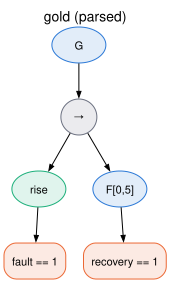

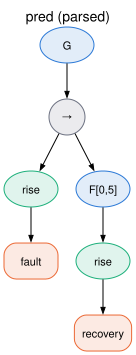

In [17]:
wC.parse()

### C.2 Normalise

- type source: **context**
- Boolean signals: `['fault', 'recovery']`
- numeric signals: `[]`
- time scale factor: **1** (all bounds already integers)

,before,after normalisation
gold,"G((rise((fault == 1)) -> F[0,5]((recovery == 1))))","G((rise(fault) -> F[0,5](recovery)))"
pred,"G((rise(fault) -> F[0,5](rise(recovery))))","G((rise(fault) -> F[0,5](rise(recovery))))"


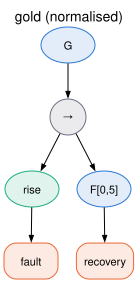

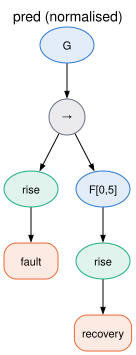

In [18]:
wC.normalise()

### C.3 Syntactic stage

In [19]:
wC.syntactic()

,canonical form
gold,"G((rise(fault) -> F[0,5](recovery)))"
pred,"G((rise(fault) -> F[0,5](rise(recovery))))"


Canonical forms **differ** → this proves nothing; go to the solvers.

### C.4 SPOT

#### 4a  Past elimination

,definition,SPOT constraint
aux signal,,
aux__0,aux__0 ≡ Y(fault),"(!""aux__0"" & G(X(""aux__0"") <-> (""fault"")))"
aux__1,aux__1 ≡ Y(recovery),"(!""aux__1"" & G(X(""aux__1"") <-> (""recovery"")))"


,past-free formula
gold,"G(((fault & !aux__0) -> F[0,5](recovery)))"
pred,"G(((fault & !aux__0) -> F[0,5]((recovery & !aux__1))))"


#### 4b  Predicate abstraction

_Only Boolean signals: every atom is already a proposition._

,propositional formula
gold,"G(((fault & !aux__0) -> F[0,5](recovery)))"
pred,"G(((fault & !aux__0) -> F[0,5]((recovery & !aux__1))))"


... (2 outputs left out)

#### 4d  Automata and containment

,states,edges,language empty?
automaton for,,,
A ∧ gold,13,48,False
A ∧ pred,20,72,False
A ∧ gold ∧ ¬pred,50,192,False
A ∧ pred ∧ ¬gold,1,0,True


gold ⊆ pred: **False** &nbsp;&nbsp; pred ⊆ gold: **True**

Büchi automaton for **A ∧ gold** (accepting edges marked; `!` = negation):

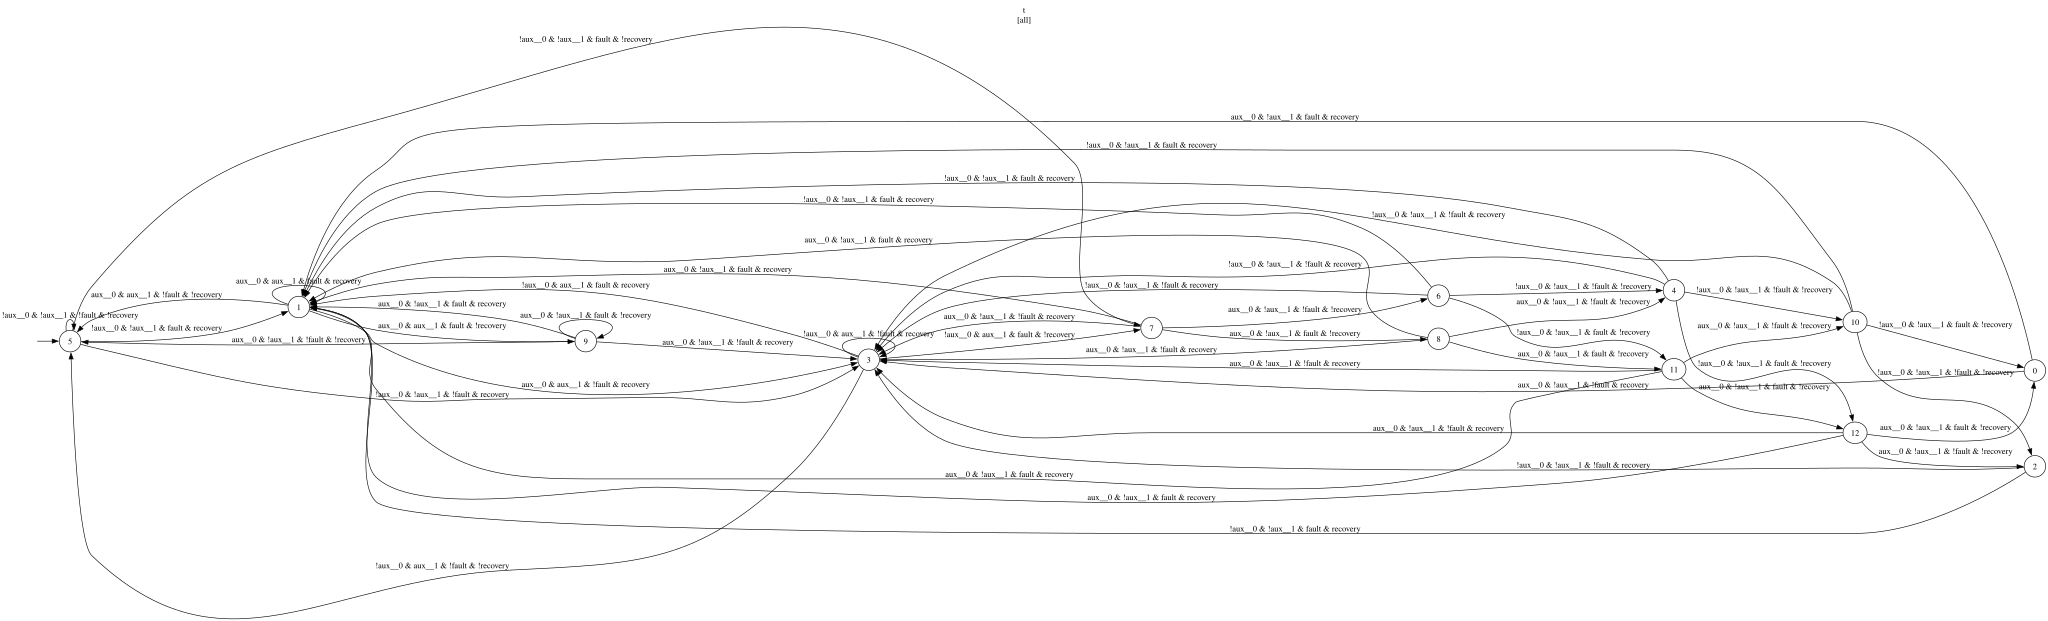

**Counterexample from `A ∧ gold ∧ ¬pred`** — an infinite trace in lasso form (steps 0–5, then a cycle of length 1 repeated forever); `·` = don't care:

,t=0,t=1,t=2,t=3,t=4,t=5,t=6,t=7
fault,0,1,0,0,0,1,1,1
recovery,1,1,1,1,1,1,1,1
aux__0,0,0,1,0,0,0,1,1
aux__1,0,1,1,1,1,1,1,1


In [20]:
wC.spot()

### C.5 STLSat

In [21]:
wC.stlsat()

#### 5a  Unbounded operators → horizon

B = largest finite horizon = **5**, so H = 2·5 + 10 = **20**. Verdict will be flagged `bounded_approx`.

,capped
gold,"G[0,20]((rise(fault) -> F[0,5](recovery)))"
pred,"G[0,20]((rise(fault) -> F[0,5](rise(recovery))))"


#### 5b  Past elimination + until rewrite (standard → STLSat-native inclusive)

,past-free,after until rewrite
gold,"G[0,20](((fault & !aux__0) -> F[0,5](recovery)))","G[0,20](((fault & !aux__0) -> F[0,5](recovery)))"
pred,"G[0,20](((fault & !aux__0) -> F[0,5]((recovery & !aux__1))))","G[0,20](((fault & !aux__0) -> F[0,5]((recovery & !aux__1))))"


Definition window: formulas read up to R = **25**; T = R + Σ h(defs) + 1 = **26** → constraints on `G[0,25]`.

... (5 outputs left out)

`Q2` → `SMT result: Some(false)` (DURATION_SEC: 0.012298) ⇒ **UNSAT**

gold ⊆ pred: **False** &nbsp;&nbsp; pred ⊆ gold: **True**

**Counterexample for Q1** (from `--trace-extraction`, which only the tableau engine offers; a finite trace up to the horizon; `·` = not fixed by the solver):

,t=0,t=1,t=2,t=3,t=4,t=5,t=6,t=7,t=8,t=9,t=10,t=11,t=12,t=13,t=14,t=15,t=16,t=17,t=18,t=19,t=20,t=21,t=22,t=23,t=24,t=25
fault,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1
recovery,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
aux__0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1
aux__1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


### C.6 Pipeline verdict

In [22]:
wC.verdict();

,MR-065
syntactic_equal,False
spot_status,OK
spot_verdict,PRED_STRONGER
spot_ms,3.624208
spot_exact,True
stlsat_status,OK
stlsat_verdict,PRED_STRONGER
stlsat_ms,37.178
stlsat_bounded_approx,True
stlsat_horizon,20


---
## D · MR-019 — Bounded until with arithmetic

`G[20,50]((x1 + x2 <= 1.5) U[2,4] (x3 > 2))` vs the same with `U[0,4]`. Stage 4c shows SPOT's encoding of bounded until with X-steps (`G[0:1]`, `X[2]`). Stage 5b shows the rewrite into STLSat's inclusive until. The arithmetic term `x1 + x2` becomes a single linear term in the abstraction.

In [23]:
wD = Walkthrough('MR-019')

**MR-019** · human decision: `fail_semantic`

- gold: `G[20,50](((x1 + x2) <= 1.5) U[2,4](x3 > 2))`
- pred: `G[20,50]((x1 + x2 <= 1.5) U[0,4] (x3 > 2))`
- signal context: _Numeric: `x1`, `x2`, `x3`. Time: abstract benchmark time units. Use these exact identifiers; do not create aliases._

### D.1 Parse

**gold** — 28 tokens: `G` `[` `20` `,` `50` `]` `(` `(` `(` `x1` `+` `x2` `)` `<=` `3/2` `)` `U` `[` `2` `,` `4` `]` `(` `x3` `>` `2` `)` `)`

**pred** — 26 tokens: `G` `[` `20` `,` `50` `]` `(` `(` `x1` `+` `x2` `<=` `3/2` `)` `U` `[` `0` `,` `4` `]` `(` `x3` `>` `2` `)` `)`

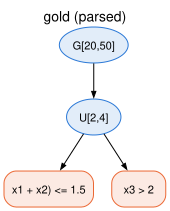

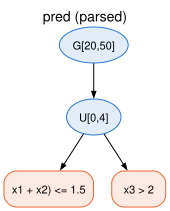

In [24]:
wD.parse()

### D.2 Normalise

In [25]:
wD.normalise()

- type source: **context**
- Boolean signals: `[]`
- numeric signals: `['x1', 'x2', 'x3']`
- time scale factor: **1** (all bounds already integers)

,before,after normalisation
gold,"G[20,50]((((x1 + x2) <= 1.5) U[2,4] (x3 > 2)))","G[20,50]((((x1 + x2) <= 1.5) U[2,4] (x3 > 2)))"
pred,"G[20,50]((((x1 + x2) <= 1.5) U[0,4] (x3 > 2)))","G[20,50]((((x1 + x2) <= 1.5) U[0,4] (x3 > 2)))"


_Normalisation changed nothing for this pair._

### D.3 Syntactic stage

In [26]:
wD.syntactic()

,canonical form
gold,"G[20,50]((((x1 + x2) <= 1.5) U[2,4] (x3 > 2)))"
pred,"G[20,50]((((x1 + x2) <= 1.5) U[0,4] (x3 > 2)))"


Canonical forms **differ** → this proves nothing; go to the solvers.

### D.4 SPOT

In [27]:
wD.spot()

#### 4a  Past elimination

_No past operators or edges: nothing to eliminate._

#### 4b  Predicate abstraction

,stands for
SPOT atom,
"""x1+x2>1.5""",x1+x2 > 3/2
"""x3>2""",x3 > 2


Ordering axioms: _none needed (no two atoms over the same term)_

Abstraction exact: **True** 

,propositional formula
gold,"G[20,50]((!x1+x2>1.5 U[2,4] x3>2))"
pred,"G[20,50]((!x1+x2>1.5 U[0,4] x3>2))"


... (3 outputs left out)

,states,edges,language empty?
automaton for,,,
A ∧ gold,113,174,False
A ∧ pred,166,284,False
A ∧ gold ∧ ¬pred,1,0,True
A ∧ pred ∧ ¬gold,261,568,False


gold ⊆ pred: **True** &nbsp;&nbsp; pred ⊆ gold: **False**

**Counterexample from `A ∧ pred ∧ ¬gold`** — an infinite trace in lasso form (steps 0–49, then a cycle of length 1 repeated forever); `·` = don't care:

,t=0,t=1,t=2,t=3,t=4,t=5,t=6,t=7,t=8,t=9,t=10,t=11,t=12,t=13,t=14,t=15,t=16,t=17,t=18,t=19,t=20,t=21,t=22,t=23,t=24,t=25,t=26,t=27,t=28,t=29,t=30,t=31,t=32,t=33,t=34,t=35,t=36,t=37,t=38,t=39,t=40,t=41,t=42,t=43,t=44,t=45,t=46,t=47,t=48,t=49,t=50,t=51
x1+x2>1.5,·,·,·,·,·,·,·,·,·,·,·,·,·,·,·,·,·,·,·,·,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1
x3>2,·,·,·,·,·,·,·,·,·,·,·,·,·,·,·,·,·,·,·,·,0,0,0,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,0,1,1,1,1,1


### D.5 STLSat

In [28]:
wD.stlsat()

#### 5a  Unbounded operators → horizon

_All operators bounded: exact, no capping._

#### 5b  Past elimination + until rewrite (standard → STLSat-native inclusive)

,past-free,after until rewrite
gold,"G[20,50]((((x1 + x2) <= 1.5) U[2,4] (x3 > 2)))","G[20,50]((G[0,1](((x1 + x2) <= 1.5)) & F[2,2](((((x1 + x2) <= 1.5) | (x3 > 2)) U[0,2] (x3 > 2)))))"
pred,"G[20,50]((((x1 + x2) <= 1.5) U[0,4] (x3 > 2)))","G[20,50](((((x1 + x2) <= 1.5) | (x3 > 2)) U[0,4] (x3 > 2)))"


#### 5c  The two queries (top-level conjuncts, one per line)

**Q1 = A ∧ gold ∧ ¬pred**
```
((G[20,50] ((((G[0,1] (((x1 + x2) <= 1.5)))) && ((F[2,2] (((((((x1 + x2) <= 1.5)) || ((x3 > 2)))) U[0,2] ((x3 > 2))))))))))
&& !((G[20,50] (((((((x1 + x2) <= 1.5)) || ((x3 > 2)))) U[0,4] ((x3 > 2))))))
```

... (3 outputs left out)

`Q2` → `SMT result: Some(true)` (DURATION_SEC: 0.023271) ⇒ **SAT**

gold ⊆ pred: **True** &nbsp;&nbsp; pred ⊆ gold: **False**

**Counterexample for Q2** (from `--trace-extraction`, which only the tableau engine offers; a finite trace up to the horizon; `·` = not fixed by the solver):

,other literals
t,
20,"(x1 + x2) <= 3/2, x3 > 2"
21,"(!(x1 + x2) <= 3/2), x3 > 2"
22,"(x1 + x2) <= 3/2, x3 > 2"
23,"(x1 + x2) <= 3/2, x3 > 2"
24,"(x1 + x2) <= 3/2, x3 > 2"
25,"(x1 + x2) <= 3/2, x3 > 2"
26,"(x1 + x2) <= 3/2, x3 > 2"
27,"(x1 + x2) <= 3/2, x3 > 2"
28,"(x1 + x2) <= 3/2, x3 > 2"


### D.6 Pipeline verdict

In [29]:
wD.verdict();

,MR-019
syntactic_equal,False
spot_status,OK
spot_verdict,PRED_WEAKER
spot_ms,13.379541
spot_exact,True
stlsat_status,OK
stlsat_verdict,PRED_WEAKER
stlsat_ms,43.81
stlsat_bounded_approx,False
stlsat_horizon,None


---
## E · MR-015 — Unbounded eventually and horizon capping

`G(!primary_ok -> backup_active)` vs `G(!primary_ok -> F backup_active)`. SPOT decides this exactly over infinite traces. STLSat needs bounds: B = 0, so H = 10, and both formulas are capped at `[0,10]`. The verdicts agree, but the STLSat one is flagged as an approximation.

In [30]:
wE = Walkthrough('MR-015')

**MR-015** · human decision: `fail_semantic`

- gold: `G((primary_ok = 0) -> (backup_active = 1))`
- pred: `G((primary_ok = 0) -> F(backup_active = 1))`
- signal context: _Boolean (1=true, 0=false): `primary_ok`, `backup_active`. Time: follows the requirement; unbounded operators have no finite interval. Use these exact identifiers; do not create aliases._

### E.1 Parse

**gold** — 14 tokens: `G` `(` `(` `primary_ok` `=` `0` `)` `->` `(` `backup_active` `=` `1` `)` `)`

**pred** — 15 tokens: `G` `(` `(` `primary_ok` `=` `0` `)` `->` `F` `(` `backup_active` `=` `1` `)` `)`

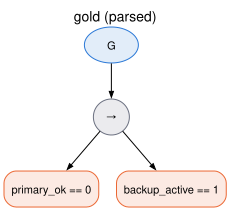

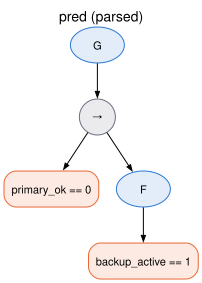

In [31]:
wE.parse()

### E.2 Normalise

- type source: **context**
- Boolean signals: `['backup_active', 'primary_ok']`
- numeric signals: `[]`
- time scale factor: **1** (all bounds already integers)

,before,after normalisation
gold,G(((primary_ok == 0) -> (backup_active == 1))),G((!primary_ok -> backup_active))
pred,G(((primary_ok == 0) -> F((backup_active == 1)))),G((!primary_ok -> F(backup_active)))


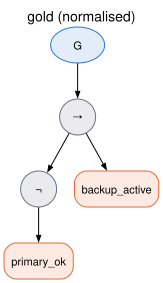

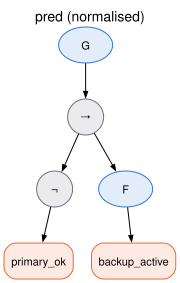

In [32]:
wE.normalise()

### E.3 Syntactic stage

In [33]:
wE.syntactic()

,canonical form
gold,G((!primary_ok -> backup_active))
pred,G((!primary_ok -> F(backup_active)))


Canonical forms **differ** → this proves nothing; go to the solvers.

### E.4 SPOT

#### 4a  Past elimination

_No past operators or edges: nothing to eliminate._

#### 4b  Predicate abstraction

_Only Boolean signals: every atom is already a proposition._

,propositional formula
gold,G((!primary_ok -> backup_active))
pred,G((!primary_ok -> F(backup_active)))


#### 4c  What SPOT receives

gold:
```
G(((!("primary_ok")) -> ("backup_active")))
```
pred:
```
G(((!("primary_ok")) -> (F("backup_active"))))
```

#### 4d  Automata and containment

,states,edges,language empty?
automaton for,,,
A ∧ gold,1,1,False
A ∧ pred,2,4,False
A ∧ gold ∧ ¬pred,1,0,True
A ∧ pred ∧ ¬gold,3,6,False


gold ⊆ pred: **True** &nbsp;&nbsp; pred ⊆ gold: **False**

Büchi automaton for **A ∧ gold** (accepting edges marked; `!` = negation):

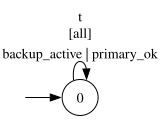

**Counterexample from `A ∧ pred ∧ ¬gold`** — an infinite trace in lasso form (no prefix; a cycle of length 2 repeated forever); `·` = don't care:

,t=0,t=1,t=2
backup_active,0,1,0
primary_ok,0,·,0


In [34]:
wE.spot()

### E.5 STLSat

In [35]:
wE.stlsat()

#### 5a  Unbounded operators → horizon

B = largest finite horizon = **0**, so H = 2·0 + 10 = **10**. Verdict will be flagged `bounded_approx`.

,capped
gold,"G[0,10]((!primary_ok -> backup_active))"
pred,"G[0,10]((!primary_ok -> F[0,10](backup_active)))"


#### 5b  Past elimination + until rewrite (standard → STLSat-native inclusive)

,past-free,after until rewrite
gold,"G[0,10]((!primary_ok -> backup_active))","G[0,10]((!primary_ok -> backup_active))"
pred,"G[0,10]((!primary_ok -> F[0,10](backup_active)))","G[0,10]((!primary_ok -> F[0,10](backup_active)))"


#### 5c  The two queries (top-level conjuncts, one per line)

... (4 outputs left out)

`Q2` → `SMT result: Some(true)` (DURATION_SEC: 0.009264) ⇒ **SAT**

gold ⊆ pred: **True** &nbsp;&nbsp; pred ⊆ gold: **False**

**Counterexample for Q2** (from `--trace-extraction`, which only the tableau engine offers; a finite trace up to the horizon; `·` = not fixed by the solver):

,t=0,t=1,t=2,t=3,t=4,t=5,t=6,t=7,t=8,t=9,t=10
backup_active,·,·,·,·,·,·,·,·,·,·,0
primary_ok,1,1,1,1,1,1,1,1,1,1,0


### E.6 Pipeline verdict

In [36]:
wE.verdict();

,MR-015
syntactic_equal,False
spot_status,OK
spot_verdict,PRED_WEAKER
spot_ms,0.724834
spot_exact,True
stlsat_status,OK
stlsat_verdict,PRED_WEAKER
stlsat_ms,19.997
stlsat_bounded_approx,True
stlsat_horizon,10


---
## Summary of the five pairs

In [37]:
rows = []
for w in [wA, wB, wC, wD, wE]:
    r = w.result
    rows.append({'pair': w.id, 'human': MR.loc[w.id, 'final_decision'], 'syntactic equal': r['syntactic_equal'],
                 'SPOT': r['spot_verdict'], 'SPOT ms': round(r['spot_ms'], 2) if r['spot_ms'] else None,
                 'STLSat': r['stlsat_verdict'], 'STLSat ms': round(r['stlsat_ms'], 2) if r['stlsat_ms'] else None,
                 'STLSat capped (H)': r['stlsat_horizon'] if r['stlsat_bounded_approx'] else '—'})
pd.DataFrame(rows).set_index('pair')

,human,syntactic equal,SPOT,SPOT ms,STLSat,STLSat ms,STLSat capped (H)
pair,,,,,,,
MR-001,pass_equivalent,True,EQUIVALENT,0.14,EQUIVALENT,16.73,10
MR-020,pass_equivalent,False,EQUIVALENT,4.19,EQUIVALENT,37.57,30
MR-065,pass_equivalent,False,PRED_STRONGER,3.62,PRED_STRONGER,37.18,20
MR-019,fail_semantic,False,PRED_WEAKER,13.38,PRED_WEAKER,43.81,—
MR-015,fail_semantic,False,PRED_WEAKER,0.72,PRED_WEAKER,20.00,10
